Dataset shape: (569, 30)

Target classes:
['malignant' 'benign']

Missing values: 0

Decision Tree - Confusion Matrix:
[[39  3]
 [ 7 65]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114


KNN - Confusion Matrix:
[[39  3]
 [ 2 70]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


Naive Bayes - Confusion Matrix:
[[38  4]
 [ 3 69]]

Classification Report:
              precision    recall  f1-sc

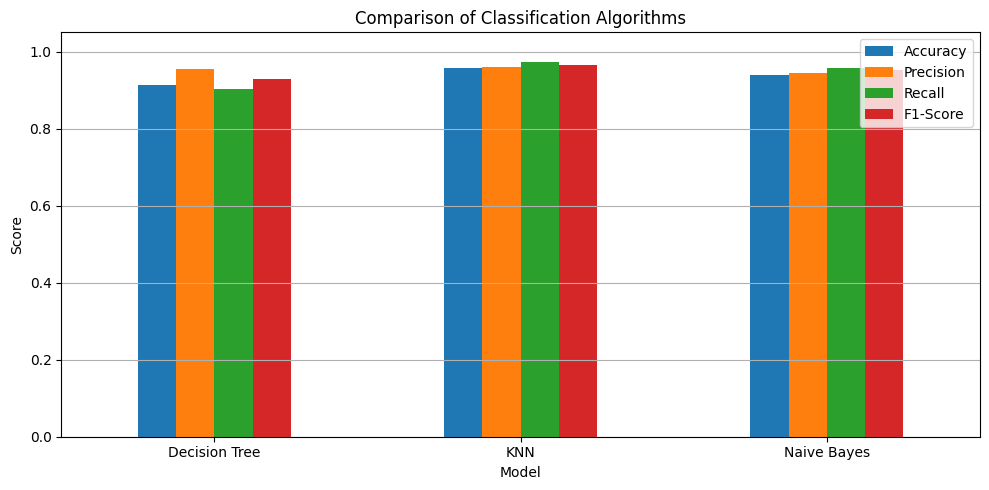

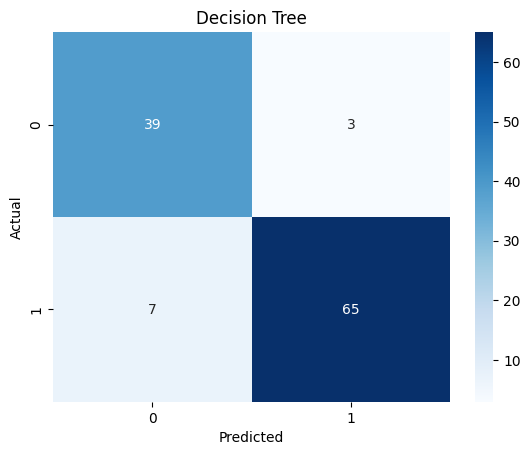

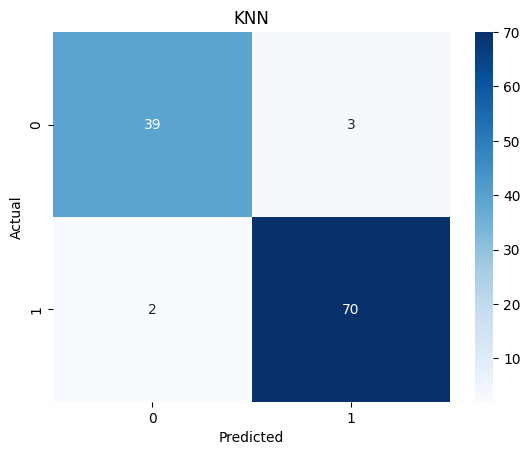

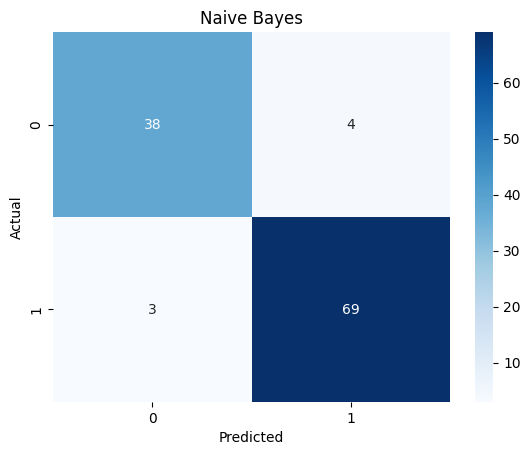


Recommended model based on F1-Score: KNN


<Figure size 640x480 with 0 Axes>

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

# Step 1: Load the real-world dataset
cancer = load_breast_cancer(as_frame=True)
X = cancer.data
y = cancer.target

print("Dataset shape:", X.shape)
print("\nTarget classes:")
print(cancer.target_names)
print("\nMissing values:", X.isnull().sum().sum())

# Step 2: Handle missing values
# Median imputation is fitted only on training data using pipelines.

# Step 3: Common stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 4: Define three classifiers
models = {
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DecisionTreeClassifier(random_state=42))
    ]),

    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Naive Bayes": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", GaussianNB())
    ])
}

results = []
confusion_matrices = {}

# Step 5 and 6: Train, predict and evaluate
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0)
    })

    confusion_matrices[name] = confusion_matrix(y_test, y_pred)

    print(f"\n{name} - Confusion Matrix:")
    print(confusion_matrices[name])

    print("\nClassification Report:")
    print(classification_report(    # classification_report -> inbuilt report containing precision, recall, F1-score, and support for each class
        y_test, y_pred,
        target_names=cancer.target_names,
        zero_division=0
    ))

# Step 7: Comparison table
comparison = pd.DataFrame(results).set_index("Model")

print("\nModel Comparison:")
print(comparison.round(4))

# Plot comparison of evaluation metrics
comparison.plot(kind="bar", figsize=(10, 5))
plt.title("Comparison of Classification Algorithms")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# Plot confusion matrices
for name, cm in confusion_matrices.items():
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    plt.figure()

# Recommend the model with the highest F1-score
best_model = comparison["F1-Score"].idxmax()
print("\nRecommended model based on F1-Score:", best_model)
